### 라이브러리 임포트

In [1]:
import numpy as np
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense
from tensorflow.keras.utils import to_categorical
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score

### 데이터 준비

In [2]:
# 붓꽃 데이터 로드
iris = load_iris()
X = iris.data[:, [0, 1, 2, 3]]
y = iris.target

In [3]:
# 4개 특성 이름을 확인
print("\nFeature Names:")
print(iris.feature_names)

# 3개 클래스의 이름을 확인
print("\nTarget Names:")
print(iris.target_names)


Feature Names:
['sepal length (cm)', 'sepal width (cm)', 'petal length (cm)', 'petal width (cm)']

Target Names:
['setosa' 'versicolor' 'virginica']


In [4]:
# 데이터 정규화
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

In [5]:
# 라벨 원-핫 인코딩
y_encoded = to_categorical(y)

In [6]:
# 데이터 분할
X_train, X_val, y_train, y_val = train_test_split(X_scaled, y_encoded, test_size=0.3, random_state=42)
X_val, X_test, y_val, y_test = train_test_split(X_val, y_val, test_size=1/3, random_state=42)

In [7]:
print("Train set:", X_train.shape, y_train.shape)
print("Validation set:", X_val.shape, y_val.shape)
print("Test set:", X_test.shape, y_test.shape)

Train set: (105, 4) (105, 3)
Validation set: (30, 4) (30, 3)
Test set: (15, 4) (15, 3)


### 다층 신경망 모델 생성

In [8]:
model = Sequential([
    Dense(5, activation='sigmoid', input_shape=(4,)),
    Dense(5, activation='sigmoid'),
    Dense(3, activation='softmax')
])
model.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy'])
model.summary()



Model: "sequential"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 dense (Dense)               (None, 5)                 25        
                                                                 
 dense_1 (Dense)             (None, 5)                 30        
                                                                 
 dense_2 (Dense)             (None, 3)                 18        
                                                                 
Total params: 73 (292.00 Byte)
Trainable params: 73 (292.00 Byte)
Non-trainable params: 0 (0.00 Byte)
_________________________________________________________________


- 모델 타입: Sequential (가장 간단한 순차적 모델)
- 입력: 4개의 피처 (특성)
- 구조: 5개 뉴런을 가진 은닉층 2개 + 3개 뉴런을 가진 출력층 1개
- 출력: 3개의 값 (아마도 3개 클래스에 대한 확률)
- 총 학습 파라미터: 25 + 30 + 18 = 73개
- Trainable params (학습 가능한 파라미터): 73개 (모든 파라미터를 학습합니다.)
- Non-trainable params (학습 불가능한 파라미터): 0개 (예: 전이 학습 시 일부 레이어를 '얼릴' 경우 이 값이 바뀝니다.)

In [9]:
# 모델 학습
history = model.fit(X_train, y_train,
                    epochs=2000,
                    batch_size=16,
                    validation_data=(X_val, y_val),
                    verbose=0)

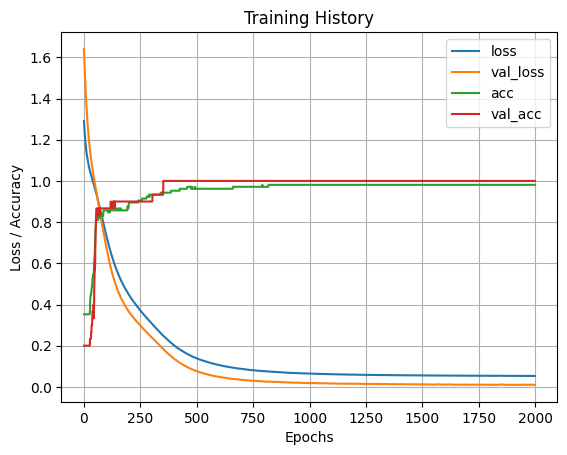

In [10]:
# 학습 과정 시각화
import matplotlib.pyplot as plt
plt.plot(history.history['loss'], label='loss')
plt.plot(history.history['val_loss'], label='val_loss')
plt.plot(history.history['accuracy'], label='acc')
plt.plot(history.history['val_accuracy'], label='val_acc')
plt.xlabel('Epochs')
plt.ylabel('Loss / Accuracy')
plt.legend()
plt.title('Training History')
plt.grid(True)
plt.show()

In [11]:
# 테스트 데이터 예측 및 정확도 평가
y_test_pred_probs = model.predict(X_test)
y_test_pred = np.argmax(y_test_pred_probs, axis=1)
y_test_true = np.argmax(y_test, axis=1)

1/1 [==============================] - 0s 41ms/step


In [12]:
accuracy_score(y_test_true, y_test_pred)

1.0